# Lab 6: Back-Test With Costs and the Files for Power BI (JPM)

**Owner:** Member 6 · **Marking items covered:** Advanced items 3 and 4, and the data behind 6. Power BI

**The question this notebook answers:** Could the best model have made money after trading costs, compared with simply holding JPM? And what do the manager's dashboards show?


## Step 1: Set up

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data
from tslab.team import build_features_jpm, make_dataset_jpm, FEATURE_GROUPS_JPM, ALL_FEATURES_JPM   # OUR features
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict, directional_accuracy,
                           directional_accuracy_test, out_of_sample_r2, rmse, mae,
                           simple_backtest, backtest_summary)
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts


import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)
print("Target stock:", config.TARGET_TICKER)

Target stock: JPM


## Step 2: The data and the walk-forward folds

Every notebook in our project uses these lines, so that every model is scored on the same days.

In [2]:
frame = load_market_data()                                              # one row per JPM trading day
dataset_all = make_dataset_jpm(frame, horizon=1)                        # includes the last row (no target yet)
latest_row = dataset_all.iloc[[-1]]                                     # kept aside for a real forecast
dataset = dataset_all.dropna(subset=["target_return"])
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))                     # expect 2789
print("Walk-forward folds         :", len(splits))                      # expect 29
print("First test day:", dataset.index[splits[0][1][0]].date(), "| last test day:", dataset.index[splits[-1][1][-1]].date())

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Rows in the modelling table: 2789
Walk-forward folds         : 29
First test day: 2019-10-08 | last test day: 2026-11-18


## Step 3: Load every prediction file

Run this notebook LAST. It reads the files that Members 2, 3, 4 and 5 push.

In [3]:
files = ["predictions_classical.csv", "predictions_ml.csv", "predictions_nn.csv"]
found = [f for f in files if (config.OUTPUT_DIR / f).exists()]
print("Found:", found, "| missing:", sorted(set(files) - set(found)))
if found:
    preds = pd.concat([pd.read_csv(config.OUTPUT_DIR / f, index_col=0, parse_dates=True) for f in found], axis=1)
    preds = preds.loc[:, ~preds.columns.duplicated()]
    scored_rows = preds.dropna().index
    print("Models:", list(preds.columns), "| common days:", len(scored_rows))

Found: ['predictions_classical.csv', 'predictions_ml.csv', 'predictions_nn.csv'] | missing: []
Models: ['Naive (no change)', 'Drift', 'Simple exponential smoothing', 'ARIMA', 'ARMA(1,0)', 'ARMAX', 'Ridge', 'Gradient boosting', 'LSTM w20 u32 d0.3', 'GRU w20 u32 d0.3', 'GRU w20 u32 d0.3 (3-seed average)'] | common days: 1789


## Step 4: Master results table

Every model plus naive, with DM and hit rate. Add the neural network rows to `outputs/metrics_by_method.csv`.

In [4]:
# Every model's predicted returns on the SAME 1,789 test days (compare_models adds the naive row itself)
predictions = {name: preds.loc[scored_rows, name] for name in preds.columns if name != "Naive (no change)"}
master = compare_models(dataset.loc[scored_rows], predictions)

actual = dataset.loc[scored_rows, "target_return"]
rows = []
for name, series in predictions.items():
    s, p = diebold_mariano(actual, series, np.zeros(len(scored_rows)))
    # a model that always predicts exactly 0 (like ARIMA(0,1,0)) never picks a direction
    p_hit = directional_accuracy_test(actual, series)[1] if (series.abs() > 1e-8).any() else np.nan
    rows.append({"Model": name, "DM statistic vs naive": s, "DM p-value": p,
                 "Verdict": dm_verdict(s, p), "Hit rate p-value": p_hit,
                 "Share of days predicted UP": (series > 0).mean()})
dm_table = pd.DataFrame(rows).set_index("Model")
master_table = master.join(dm_table)
print(f"JPM rose on {(actual > 0).mean():.1%} of the {len(scored_rows)} test days")
display(master_table.round(4))

metrics = pd.read_csv(config.OUTPUT_DIR / "metrics_by_method.csv")
nn_names = [c for c in preds.columns if c.startswith(("LSTM", "GRU"))]
nn_rows = pd.DataFrame({
    "method": nn_names, "family": "neural network",
    "rmse_price": master_table.loc[nn_names, "RMSE ($)"].values,
    "mae_price": master_table.loc[nn_names, "MAE ($)"].values,
    "r2_oos": master_table.loc[nn_names, "Out-of-sample R2 (returns)"].values,
    "directional_accuracy": master_table.loc[nn_names, "Directional accuracy"].values,
    "dm_stat": master_table.loc[nn_names, "DM statistic vs naive"].values,
    "dm_p": master_table.loc[nn_names, "DM p-value"].values,
})
nn_rows["beats_naive"] = np.where((nn_rows["dm_p"] < 0.05) & (nn_rows["dm_stat"] < 0), "Yes", "No")
metrics = pd.concat([metrics[~metrics["method"].isin(nn_names)], nn_rows], ignore_index=True)
metrics.to_csv(config.OUTPUT_DIR / "metrics_by_method.csv", index=False)
display(metrics.round(4))

JPM rose on 53.4% of the 1789 test days


,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns),DM statistic vs naive,DM p-value,Verdict,Hit rate p-value,Share of days predicted UP
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000,NaN,NaN,NaN,NaN,NaN
Drift,2.9723,2.0060,1.2481,0.5344,0.0007,-0.4113,0.6809,No significant difference,0.0039,1.0000
Simple exponential smoothing,2.9797,2.0184,1.2537,0.4902,-0.0062,1.0161,0.3097,No significant difference,0.4215,0.4567
ARIMA,2.9737,2.0128,1.2504,NaN,0.0000,1.2113,0.2259,No significant difference,NaN,0.0006
"ARMA(1,0)",2.9816,2.0193,1.2558,0.5137,-0.0092,1.1090,0.2676,No significant difference,0.2564,0.6819
ARMAX,3.0005,2.0294,1.2635,0.5271,-0.0145,1.0358,0.3004,No significant difference,0.0232,0.6395
Ridge,2.9725,2.0066,1.2484,0.5355,0.0005,-0.2353,0.8140,No significant difference,0.0029,0.9911
Gradient boosting,2.9958,2.0223,1.2591,0.5266,-0.0180,1.7619,0.0783,No significant difference,0.0262,0.8547
LSTM w20 u32 d0.3,3.0232,2.0516,1.2739,0.4925,-0.0327,3.7681,0.0002,Significantly WORSE than naive,0.5388,0.5528
GRU w20 u32 d0.3,3.0085,2.0241,1.2598,0.5238,-0.0189,1.3273,0.1846,No significant difference,0.0470,0.6356


,method,family,rmse_price,mae_price,r2_oos,directional_accuracy,dm_stat,dm_p,beats_naive
0,Naive (no change),baseline,2.9737,2.0128,0.0000,NaN,NaN,NaN,baseline
1,Drift,classical,2.9723,2.0060,0.0007,0.5344,-0.4113,0.6809,No
2,Simple exponential smoothing,classical,2.9797,2.0184,-0.0062,0.4902,1.0161,0.3097,No
3,ARIMA,classical,2.9737,2.0128,0.0000,NaN,1.2113,0.2259,No
4,"ARMA(1,0)",classical,2.9816,2.0193,-0.0092,0.5137,1.1090,0.2676,No
5,ARMAX,classical,3.0005,2.0294,-0.0145,0.5271,1.0358,0.3004,No
6,Ridge,machine learning,2.9725,2.0066,0.0005,0.5355,-0.2353,0.8140,No
7,Gradient boosting,machine learning,2.9958,2.0223,-0.0180,0.5266,1.7619,0.0783,No
8,LSTM w20 u32 d0.3,neural network,3.0232,2.0516,-0.0327,0.4925,3.7681,0.0002,No
9,GRU w20 u32 d0.3,neural network,3.0085,2.0241,-0.0189,0.5238,1.3273,0.1846,No


## Step 5: Choose the best model BEFORE looking at profits

State the rule (lowest RMSE on the common days) and apply it.

In [5]:
candidates = master_table.drop(index=["Naive (no change)"])
ranked = candidates["RMSE ($)"].sort_values()
display(ranked.round(4))
best_overall = ranked.index[0]
best_with_predictors = [m for m in ranked.index if m not in ("Drift", "Simple exponential smoothing", "ARIMA", "ARMA(1,0)")][0]
print("Lowest RMSE of all models      :", best_overall)
print("Lowest RMSE using our predictors:", best_with_predictors)
backtest_models = list(dict.fromkeys([best_overall, best_with_predictors]))

Drift                                2.9723
Ridge                                2.9725
ARIMA                                2.9737
GRU w20 u32 d0.3 (3-seed average)    2.9792
Simple exponential smoothing         2.9797
ARMA(1,0)                            2.9816
Gradient boosting                    2.9958
ARMAX                                3.0005
GRU w20 u32 d0.3                     3.0085
LSTM w20 u32 d0.3                    3.0232
Name: RMSE ($), dtype: float64

Lowest RMSE of all models      : Drift
Lowest RMSE using our predictors: Ridge


## Step 6: Back-test with 0, 5 and 10 bp

Copy Notebook 4, Step 11. Compare with buy and hold. Print the share of days the strategy is long. Save `data/backtest_curves.csv` (`date, strategy, cost_bps, cumulative_log_return`).

Drift: long on 100.0% of test days
Ridge: long on 99.1% of test days


Share of days long  Annual return  Annual volatility  \
Strategy     Cost (bp)                                                         
Drift        0                       1.000          0.174                0.3   
             5                       1.000          0.174                0.3   
             10                      1.000          0.174                0.3   
Ridge        0                       0.991          0.204                0.3   
             5                       0.991          0.199                0.3   
             10                      0.991          0.195                0.3   
Buy and hold 0                       1.000          0.174                0.3   

                        Sharpe ratio  
Strategy     Cost (bp)                
Drift        0                 0.581  
             5                 0.581  
             10                0.581  
Ridge        0                 0.681  
             5                 0.665  
             10                0.650  
Buy and hold 0                 0.581

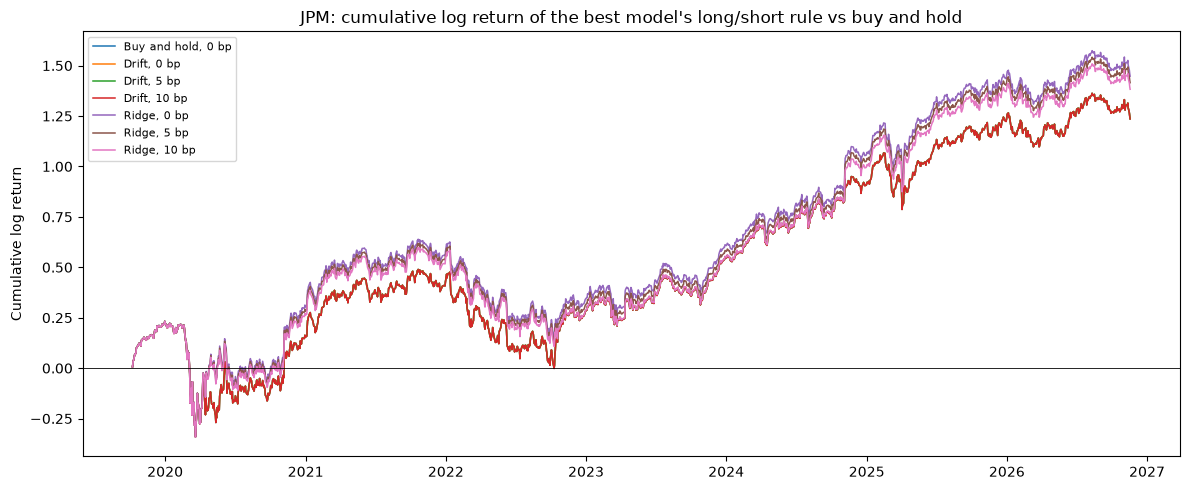

Saved 12523 rows to data/backtest_curves.csv


In [6]:
rows, curve_frames = [], []
for name in backtest_models:
    share_long = (predictions[name] > 0).mean()
    print(f"{name}: long on {share_long:.1%} of test days")
    for cost in (0, 5, 10):
        daily = simple_backtest(actual.values, predictions[name].values, cost_bps=cost)
        rows.append({"Strategy": name, "Cost (bp)": cost, "Share of days long": share_long,
                     **backtest_summary(daily).to_dict()})
        curve_frames.append(pd.DataFrame({"date": scored_rows, "strategy": name, "cost_bps": cost,
                                          "cumulative_log_return": daily.cumsum().values}))
bh = pd.Series(actual.values)
rows.append({"Strategy": "Buy and hold", "Cost (bp)": 0, "Share of days long": 1.0, **backtest_summary(bh).to_dict()})
curve_frames.append(pd.DataFrame({"date": scored_rows, "strategy": "Buy and hold", "cost_bps": 0,
                                  "cumulative_log_return": bh.cumsum().values}))
backtest_table = pd.DataFrame(rows).set_index(["Strategy", "Cost (bp)"])
display(backtest_table.round(3))

curves = pd.concat(curve_frames, ignore_index=True)
fig, ax = plt.subplots(figsize=(12, 5))
for (name, cost), g in curves.groupby(["strategy", "cost_bps"]):
    ax.plot(g["date"], g["cumulative_log_return"], label=f"{name}, {cost} bp", linewidth=1.1)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("JPM: cumulative log return of the best model's long/short rule vs buy and hold")
ax.legend(fontsize=8); ax.set_ylabel("Cumulative log return"); plt.tight_layout(); plt.show()
# the date the forecast is FOR is the next trading day
curves["date"] = frame.index[frame.index.get_indexer(pd.to_datetime(curves["date"])) + 1]
curves.to_csv(config.DATA_DIR / "backtest_curves.csv", index=False, date_format="%Y-%m-%d")
print("Saved", len(curves), "rows to data/backtest_curves.csv")

## Step 7: Why this is not a trading recommendation

The back-test is a classroom experiment, not advice to trade JPM. Five reasons:

1. **The costs are guesses.** We tried 0, 5 and 10 basis points, but real costs also include the bid-ask spread and price movement while the order fills.
2. **Short selling costs extra.** When Ridge predicts a fall it sells short, which needs borrowed shares and a borrowing fee. We ignored that fee.
3. **Choosing the best of many models is partly luck.** We compared 10 models. Even if none has real skill, one of them will look best by chance.
4. **One stock over seven years is a small sample.** The test covers only JPM from October 2019 to November 2026, a period in which the stock rose strongly. The result may not hold for other stocks or periods.
5. **A hit rate barely above 50% is fragile.** Ridge was right on 53.6% of days, almost the same as the 53.4% of days JPM rose. A small change in market conditions could remove the edge.

Most importantly, Ridge was long on 99.1% of days, so it was almost the same as buy and hold. Its higher return (20.4% a year against 17.4%) comes from the roughly 16 days it was short, which is far too few to call skill. The Diebold-Mariano test (p = 0.81) confirms that Ridge's forecasts are not significantly better than the naive forecast.

## Step 8: forecast_advanced.csv

`date, period, actual_close, naive, ... one price column per model and NN setting ..., lower, upper`. `period` is `backtest` or `future`.

In [7]:
target_day = frame.index[frame.index.get_indexer(scored_rows) + 1]
close_today = dataset.loc[scored_rows, "close"]
back = pd.DataFrame({"date": target_day, "period": "backtest",
                     "actual_close": dataset.loc[scored_rows, "target_close"].values,
                     "naive": close_today.values})
for name in predictions:
    back[name] = (close_today * np.exp(predictions[name])).values
q = pd.read_csv(config.OUTPUT_DIR / "predictions_quantile.csv", parse_dates=["date"]).set_index("date")
back["lower"] = q["lower"].reindex(back["date"]).values
back["upper"] = q["upper"].reindex(back["date"]).values

inter = pd.read_csv(config.DATA_DIR / "forecast_intermediate.csv", parse_dates=["date"])
nnpath = pd.read_csv(config.OUTPUT_DIR / "forecast_nn_path.csv", parse_dates=["date"])
future = pd.DataFrame({"date": inter["date"], "period": "future", "actual_close": np.nan,
                       "naive": inter["naive"],
                       "Simple exponential smoothing": inter["ses"],
                       "ARIMA": inter["arima"],
                       "Ridge": inter["ridge"],
                       "Gradient boosting": inter["gradient_boosting"],
                       "GRU w20 u32 d0.3": nnpath["gru_path"].values,
                       "lower": inter["lower"], "upper": inter["upper"]})
advanced = pd.concat([back, future], ignore_index=True)
advanced.to_csv(config.DATA_DIR / "forecast_advanced.csv", index=False, date_format="%Y-%m-%d")
print(advanced.shape); display(advanced.head(2)); display(advanced.tail(2))

(1852, 16)


,date,period,actual_close,naive,Drift,Simple exponential smoothing,ARIMA,"ARMA(1,0)",ARMAX,Ridge,Gradient boosting,LSTM w20 u32 d0.3,GRU w20 u32 d0.3,GRU w20 u32 d0.3 (3-seed average),lower,upper
0,2019-10-09,backtest,93.649918,92.976440,93.040417,92.996313,92.976440,93.072870,93.005227,93.048550,93.455166,93.092972,93.532047,93.329167,91.33884,94.553699
1,2019-10-10,backtest,94.963669,93.649918,93.714358,93.643797,93.649918,93.698585,93.764647,93.714453,93.549745,93.626515,93.746484,93.901662,92.06621,94.866388


,date,period,actual_close,naive,Drift,Simple exponential smoothing,ARIMA,"ARMA(1,0)",ARMAX,Ridge,Gradient boosting,LSTM w20 u32 d0.3,GRU w20 u32 d0.3,GRU w20 u32 d0.3 (3-seed average),lower,upper
1850,2027-02-22,future,NaN,320.220001,NaN,320.40882,320.220001,NaN,NaN,335.801993,345.193239,NaN,330.603910,NaN,295.077244,395.669681
1851,2027-02-23,future,NaN,320.220001,NaN,320.40882,320.220001,NaN,NaN,335.956826,344.193854,NaN,335.408061,NaN,296.166147,390.334323


## Step 9: powerbi_basic_chart.csv

The last 252 actual closes plus the 63 forecast days: `date, actual_close, forecast, lower, upper`.

In [8]:
basic = pd.read_csv(config.DATA_DIR / "forecast_basic.csv", parse_dates=["date"])
hist = frame[["Close"]].iloc[-252:].reset_index()
hist.columns = ["date", "actual_close"]
chart = pd.concat([hist, basic], ignore_index=True)
# join the lines: the forecast starts at the last actual close
chart.loc[len(hist) - 1, ["forecast", "lower", "upper"]] = hist["actual_close"].iloc[-1]
chart.to_csv(config.DATA_DIR / "powerbi_basic_chart.csv", index=False, date_format="%Y-%m-%d")
print(chart.shape); display(chart.iloc[249:254])

(315, 5)


,date,actual_close,forecast,lower,upper
249,2026-11-17,329.959991,NaN,NaN,NaN
250,2026-11-18,324.109985,NaN,NaN,NaN
251,2026-11-19,320.220001,320.220001,320.220001,320.220001
252,2026-11-20,NaN,320.452422,312.749979,327.532895
253,2026-11-23,NaN,320.882121,312.055706,331.233630


## Conclusion

**No model beats the naive forecast for JPM.** On 1,789 test days that no model saw (October 2019 to November 2026), none of the 10 models had a significantly smaller error than "tomorrow equals today". The lowest errors were Drift ($2.9723) and Ridge ($2.9725), against $2.9737 for naive, a difference of less than one cent. Their DM p-values (0.68 and 0.81) show the difference is just noise. The only significant result was the LSTM, which was significantly *worse* than naive (p = 0.0002).

**The back-test does not change this.** Drift is long every day, so it is identical to buy and hold (17.4% a year, Sharpe 0.58). Ridge earned 20.4% a year (19.5% after 10 bp of costs, Sharpe 0.65), but because it was long 99.1% of the time, this small extra return comes from a handful of days and is not evidence of skill. Costs barely affected Ridge because it rarely changed position.

**What the manager should take away:** JPM's daily price behaves close to a random walk, and our predictors (the market, sector funds, rates, oil, gold, VIX) do not forecast the next day's move. The 63-day forecast should be read as roughly "no change", and the client should plan around the 10%–90% range rather than the central line. This is an honest negative result, which the brief accepts as a valid finding.